In [ ]:
4.2: UNSHARP MASKING

Selected Image: /content/image.png


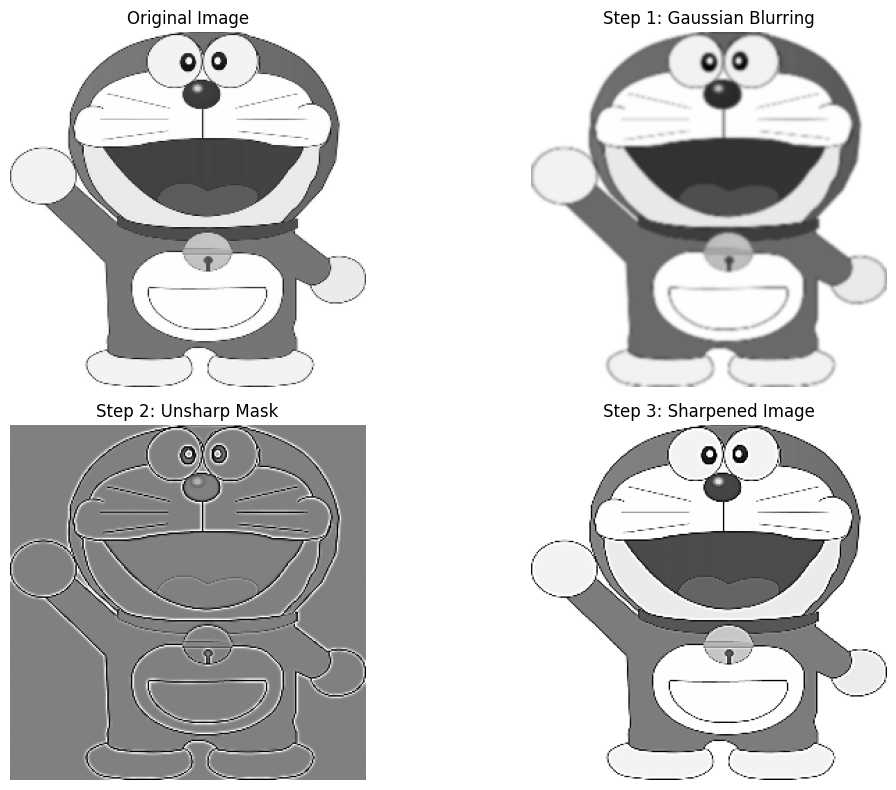

Unsharp Masking Completed Successfully!
Output saved at: /content/Assignment_4_2_Unsharp_Masking.png


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

# STEP 1: Find and Load Image
image_files = []

for ext in ["*.png", "*.jpg", "*.jpeg", "*.bmp"]:
    image_files.extend(glob.glob("/content/" + ext))

if len(image_files) == 0:
    raise FileNotFoundError(
        "No image found! Please upload your image to Colab Files."
    )

# Select image.png if available; otherwise use first image
selected_file = next(
    (f for f in image_files if os.path.basename(f).lower() == "image.png"),
    image_files[0]
)

print("Selected Image:", selected_file)

image = cv2.imread(selected_file, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Unable to read the selected image.")

image = cv2.resize(image, (256, 256))

# STEP 2: Gaussian Blurring
blurred = cv2.GaussianBlur(image, (5, 5), 1.0)

# STEP 3: Generate Unsharp Mask
image_float = image.astype(np.float32)
blurred_float = blurred.astype(np.float32)

unsharp_mask = image_float - blurred_float

# STEP 4: Apply Unsharp Masking
k = 1.0

sharpened = image_float + k * unsharp_mask
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

# ==========================================
# DISPLAY ALL RESULTS
# ==========================================

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Step 1: Gaussian Blurring")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(unsharp_mask, cmap="gray", vmin=-50, vmax=50)
plt.title("Step 2: Unsharp Mask")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(sharpened, cmap="gray")
plt.title("Step 3: Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# SAVE FINAL OUTPUT
# ==========================================

output_file = "/content/Assignment_4_2_Unsharp_Masking.png"

cv2.imwrite(output_file, sharpened)

print("Unsharp Masking Completed Successfully!")
print("Output saved at:", output_file)